# Comparable Baseline: BERT Mini with 128-Token Input

Select a GPU in Colab and run the cells in order. Install dependencies in a fresh runtime; if libraries have already been imported, restart the session after installation.

The architecture is `google/bert_uncased_L-4_H-256_A-4`: 4 layers, hidden size 256, 4 attention heads, and a 5-class output; all weights are fine-tuned. Only `reviewText` is provided to the model. Uncased tokenization, truncation to 128 tokens (including special tokens), dynamic padding, and attention masks are retained. Negation words, stopwords, and punctuation are not removed.

**Protocol:** First select 50% of valid data using stratification, then split into train/validation/test at a 70/15/15 ratio. Row membership is saved. Reuse these exact splits in subsequent experiments. Because the data selection changed relative to the older version, older results are not directly comparable to this controlled baseline.

**Training:** Up to 4 epochs, early stopping after 2 evaluations without improvement, full validation at the end of each epoch, and selection based on the best Micro-F1 as in the initial code. For single-label classification, Micro-F1 equals accuracy; also review Macro-F1 and per-class metrics to assess class imbalance. The test set is evaluated only after final model selection and is disabled by default.

**Performance:** Training batch size 32 is retained; evaluation batch size 128, mixed precision, padding to multiples of 8, and pinned-memory data loading are used. Checkpoints are written to local disk and copied to Drive after each epoch. Increasing the training batch size to 64 is a separate experiment; its speed advantage is not guaranteed. If evaluation runs out of memory, reduce `EVAL_BATCH_SIZE` to 64 or 32. Training for more epochs also extends the linear learning-rate schedule.

This notebook does not contain a precomputed training result; actual outputs are recorded when you execute it with your data and GPU.


In [1]:

# Remove packages that conflict with Transformers 4.x
%pip uninstall -y gradio gradio-client diffusers

# Install compatible NLP dependencies
%pip install -q \
    "transformers==4.57.1" \
    "huggingface-hub>=0.34,<1.0" \
    "datasets>=3,<5" \
    "accelerate>=1,<2" \
    scikit-learn gdown pyarrow matplotlib


Found existing installation: gradio 6.31.0
Uninstalling gradio-6.31.0:
  Successfully uninstalled gradio-6.31.0
Found existing installation: gradio_client 2.7.2
Uninstalling gradio_client-2.7.2:
  Successfully uninstalled gradio_client-2.7.2
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1


In [2]:
# %pip install -q "transformers==4.57.1" "datasets>=3,<5" "accelerate>=1,<2" scikit-learn gdown pyarrow matplotlib


## 1. Download and Load Data
The original data download and loading procedure is retained.


In [3]:
from pathlib import Path
import gdown

DATA_DIR = Path("/content/amazon_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

FILE_ID = "1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW"

# Preserve the original filename and extension.
downloaded_path = gdown.download(
    id=FILE_ID,
    output=str(DATA_DIR) + "/",
    quiet=False,
)

if downloaded_path is None:
    raise RuntimeError("Download failed. Check the file's sharing permissions.")

data_path = Path(downloaded_path)

print("Filename:", data_path.name)
print(f"File size: {data_path.stat().st_size / (1024**2):,.1f} MB")


Downloading...
From (original): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW
From (redirected): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW&confirm=t&uuid=cddcf5c3-8c53-4bd3-8ab2-b9aee76aa4cc
To: /content/amazon_data/train_data.csv
100%|██████████| 635M/635M [00:08<00:00, 75.1MB/s]


Filename: train_data.csv
File size: 605.2 MB


In [4]:
import gzip
import json
import zipfile

import pandas as pd
from IPython.display import display

KEEP_COLUMNS = ["reviewText", "summary", "overall"]


def read_reviews(stream, filename):
    name = filename.lower()

    if name.endswith(".csv"):
        return pd.read_csv(
            stream,
            usecols=lambda column: column in KEEP_COLUMNS,
        )

    if name.endswith((".json", ".jsonl", ".ndjson")):
        # Inspect the first line to distinguish JSON Lines from a JSON array.
        first_line = stream.readline().strip()
        stream.seek(0)

        if first_line.startswith(b"["):
            frame = pd.read_json(stream)
            return frame.loc[:, frame.columns.intersection(KEEP_COLUMNS)]

        try:
            first_record = json.loads(first_line)
            is_json_lines = isinstance(first_record, dict)
        except json.JSONDecodeError:
            is_json_lines = False

        if is_json_lines:
            # Read in chunks to reduce temporary memory usage.
            chunks = pd.read_json(stream, lines=True, chunksize=50_000)
            frames = [
                chunk.loc[:, chunk.columns.intersection(KEEP_COLUMNS)]
                for chunk in chunks
            ]
            return pd.concat(frames, ignore_index=True)

        frame = pd.read_json(stream)
        return frame.loc[:, frame.columns.intersection(KEEP_COLUMNS)]

    raise ValueError(f"Unsupported file format: {filename}")


if zipfile.is_zipfile(data_path):
    with zipfile.ZipFile(data_path) as archive:
        candidates = [
            name for name in archive.namelist()
            if not name.startswith("__MACOSX/")
            and name.lower().endswith((".csv", ".json", ".jsonl", ".ndjson"))
        ]

        if len(candidates) != 1:
            raise ValueError(
                f"Expected one data file inside ZIP. Found: {candidates}"
            )

        with archive.open(candidates[0]) as stream:
            df = read_reviews(stream, candidates[0])

elif data_path.name.lower().endswith(".gz"):
    with gzip.open(data_path, "rb") as stream:
        df = read_reviews(stream, data_path.stem)

else:
    with data_path.open("rb") as stream:
        df = read_reviews(stream, data_path.name)

required_columns = {"reviewText", "overall"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print(f"Number of reviews: {len(df):,}")
print("Loaded columns:", df.columns.tolist())
display(df.head())


Number of reviews: 838,944
Loaded columns: ['overall', 'reviewText', 'summary']


,overall,reviewText,summary
0,2,I have an older URC-WR7 remote and thought thi...,Cannot Learn
1,5,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?
2,4,Got them and only 2 of them worked. company ca...,Works Good and programs easy.
3,5,I got tired of the remote being on the wrong s...,Same as TWC remote
4,5,After purchasing cheap cords from another webs...,Good Quality Cord


## 2. Fixed Experimental Settings
Keep these settings and data splits fixed when comparing architectures. Each run has a separate output directory.


In [5]:
import os, json, hashlib, shutil, time, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import transformers, datasets, sklearn
from sklearn.model_selection import train_test_split
from transformers import set_seed
from google.colab import drive

SEED = 42
MODEL_NAME = "google/bert_uncased_L-4_H-256_A-4"
MAX_LENGTH = 128
TRAIN_BATCH_SIZE = 64
EVAL_BATCH_SIZE = 128
EPOCHS = 4
LEARNING_RATE = 2e-5
RUN_TEST = False  # Enable only after the model-development decisions are final.
# For future runs, set this to the existing splits directory printed below.
REUSE_SPLITS_DIR = None

set_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Select Runtime > Change runtime type > GPU in Colab.")
drive.mount('/content/drive')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
LOCAL_RUN_DIR = Path('/content/amazon_baseline_runs') / RUN_ID
RUN_DIR = Path('/content/drive/MyDrive/amazon_sentiment/half_data_baselines') / RUN_ID
SPLITS_DIR = RUN_DIR / 'splits'
CHECKPOINT_DIR = LOCAL_RUN_DIR / 'checkpoints'
for directory in [LOCAL_RUN_DIR, RUN_DIR, SPLITS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0))
print('Results:', RUN_DIR)


Mounted at /content/drive
GPU: Tesla T4
Results: /content/drive/MyDrive/amazon_sentiment/half_data_baselines/20261104_144754_022842


## 3. Cleaning, Half-Data Selection, and Stratified Splitting
The original source-row ID is retained before resetting the index. The split is row-based; evaluating generalization to unseen users or products would require a separate group-based split experiment. Potentially duplicate review texts are not removed, preserving the original cleaning protocol; text overlap is reported.


In [6]:
data = df[['reviewText', 'overall']].copy()
data['source_row_id'] = np.arange(len(data), dtype=np.int64)
data['overall'] = pd.to_numeric(data['overall'], errors='coerce')
data['reviewText'] = data['reviewText'].astype('string').str.strip()
valid = (data['overall'].isin([1,2,3,4,5]) & data['reviewText'].notna()
         & data['reviewText'].ne('')).fillna(False)
data = data.loc[valid].copy()
data['overall'] = data['overall'].astype('int64')
data['labels'] = data['overall'] - 1
data = data.reset_index(drop=True)
# Include cleaned text, labels and row identity in the data fingerprint.
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(data, index=False).values.tobytes()
).hexdigest()

if REUSE_SPLITS_DIR is None:
    selected_df, _ = train_test_split(
        data, train_size=0.5, stratify=data['labels'], random_state=SEED)
    train_df, remaining = train_test_split(
        selected_df, test_size=0.30,
        stratify=selected_df['labels'], random_state=SEED)
    val_df, test_df = train_test_split(
        remaining, test_size=0.50, stratify=remaining['labels'], random_state=SEED)
else:
    old_dir = Path(REUSE_SPLITS_DIR)
    previous = json.loads((old_dir/'split_manifest.json').read_text())
    assert previous['data_fingerprint'] == fingerprint, 'Input data changed.'
    assert previous['seed'] == SEED, 'Split seed changed.'
    train_df, val_df, test_df = [pd.read_parquet(old_dir/f'{s}.parquet')
                                for s in ['train','validation','test']]
    selected_df = pd.concat([train_df,val_df,test_df], ignore_index=True)

split_frames = {'train': train_df, 'validation': val_df, 'test': test_df}
id_sets = [set(f['source_row_id']) for f in split_frames.values()]
assert all(len(ids)==len(frame) for ids,frame in zip(id_sets,split_frames.values()))
assert all(id_sets[i].isdisjoint(id_sets[j]) for i,j in [(0,1),(0,2),(1,2)])
assert sum(map(len,split_frames.values())) == len(data)//2
split_fingerprint = hashlib.sha256(b''.join(
    np.sort(f['source_row_id'].to_numpy(dtype=np.int64)).tobytes()
    for f in split_frames.values())).hexdigest()
for name, frame in split_frames.items():
    frame.reset_index(drop=True).to_parquet(SPLITS_DIR/f'{name}.parquet', index=False)
manifest = {'seed': SEED, 'data_fingerprint':fingerprint,
            'split_fingerprint':split_fingerprint, 'sampling_fraction':0.5,
            'ratios':[0.70,0.15,0.15],
            'sizes':{name:len(f) for name,f in split_frames.items()}}
(SPLITS_DIR/'split_manifest.json').write_text(json.dumps(manifest,indent=2))
def percentages(frame):
    return frame['overall'].value_counts(normalize=True).reindex(range(1,6),fill_value=0)*100
display(pd.DataFrame({'All usable (%)':percentages(data),
                      'Selected half (%)':percentages(selected_df),
                      **{name+' (%)':percentages(f) for name,f in split_frames.items()}}).round(3))
print('Usable:',len(data), '| Selected:',len(selected_df))
print('Sizes:', manifest['sizes'])
print('Reuse these splits:', SPLITS_DIR)
text_sets = {name:set(f['reviewText']) for name,f in split_frames.items()}
duplicate_overlap = {f'{a} vs {b}':len(text_sets[a]&text_sets[b])
    for a,b in [('train','validation'),('train','test'),('validation','test')]}
print('Number of distinct identical texts shared between splits:',duplicate_overlap)
(RUN_DIR/'duplicate_text_overlap.json').write_text(json.dumps(duplicate_overlap,indent=2))
del text_sets, df, data, selected_df


,All usable (%),Selected half (%),train (%),validation (%),test (%)
overall,,,,,
1,9.887,9.887,9.887,9.887,9.889
2,6.765,6.765,6.765,6.766,6.764
3,9.683,9.683,9.683,9.684,9.684
4,18.656,18.656,18.656,18.655,18.657
5,55.008,55.008,55.008,55.009,55.007


Usable: 838944 | Selected: 419472
Sizes: {'train': 293630, 'validation': 62921, 'test': 62921}
Reuse these splits: /content/drive/MyDrive/amazon_sentiment/half_data_baselines/20261104_144754_022842/splits
Number of distinct identical texts shared between splits: {'train vs validation': 1732, 'train vs test': 1714, 'validation vs test': 386}


## 4. Tokenization and Core Architecture
The test set is not tokenized or evaluated during development. Each batch is padded dynamically to the longest item in that batch, rounded to a multiple of 8.


In [7]:
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
set_seed(SEED)  # Reproduce the randomly initialized classification head.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=5, use_safetensors=True,
    id2label={i:str(i+1) for i in range(5)},
    label2id={str(i+1):i for i in range(5)})
for parameter in model.parameters():
    parameter.requires_grad = True
assert model.config.num_hidden_layers == 4
assert model.config.hidden_size == 256
assert model.config.num_attention_heads == 4
print('Parameters:',format(sum(p.numel() for p in model.parameters()),','))

def tokenize_batch(batch):
    return tokenizer(batch['reviewText'], truncation=True,
                     max_length=MAX_LENGTH, padding=False)
raw_datasets = DatasetDict({name:Dataset.from_pandas(
    frame[['reviewText','labels']],preserve_index=False)
    for name,frame in [('train',train_df),('validation',val_df)]})
tokenized_datasets = raw_datasets.map(
    tokenize_batch, batched=True, batch_size=1000,
    remove_columns=['reviewText'], desc='Tokenizing reviews')
data_collator = DataCollatorWithPadding(tokenizer=tokenizer,pad_to_multiple_of=8)
print(tokenized_datasets)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-4_H-256_A-4 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parameters: 11,171,845


Tokenizing reviews:   0%|          | 0/293630 [00:00<?, ? examples/s]

Tokenizing reviews:   0%|          | 0/62921 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 293630
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 62921
    })
})


## 5. Evaluation Metrics and Training Configuration
Validation covers the entire validation set on every evaluation. Both checkpoint saving and evaluation occur at the end of each epoch so that the best checkpoint can be selected and reloaded correctly. Early stopping monitors Micro-F1.


In [8]:
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             classification_report, confusion_matrix)
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback, TrainerCallback

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    if isinstance(logits,tuple):
        logits = logits[0]
    predictions = np.argmax(logits,axis=-1)
    return {
        'micro_f1':f1_score(labels,predictions,labels=list(range(5)),average='micro',zero_division=0),
        'macro_f1':f1_score(labels,predictions,labels=list(range(5)),average='macro',zero_division=0),
        'accuracy':accuracy_score(labels,predictions),
        'mae':mean_absolute_error(labels,predictions),
    }

class DriveBackupCallback(TrainerCallback):
    def on_save(self,args,state,control,**kwargs):
        # Copy only after a complete local checkpoint has been written.
        source = Path(args.output_dir)/f'checkpoint-{state.global_step}'
        target = RUN_DIR/'checkpoints'/source.name
        shutil.copytree(source,target,dirs_exist_ok=True)
        best_name = Path(state.best_model_checkpoint).name if state.best_model_checkpoint else None
        for old in target.parent.glob('checkpoint-*'):
            if old.name not in {target.name,best_name}:
                shutil.rmtree(old)
        pd.DataFrame(state.log_history).to_csv(RUN_DIR/'training_history.csv',index=False)
        return control

use_bf16 = torch.cuda.is_bf16_supported()
training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=EPOCHS, learning_rate=LEARNING_RATE,
    weight_decay=0.01, warmup_ratio=0.06, lr_scheduler_type='linear',
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=1,
    fp16=not use_bf16, bf16=use_bf16,
    optim='adamw_torch',
    eval_strategy='epoch', save_strategy='epoch', save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model='micro_f1',
    greater_is_better=True,
    logging_strategy='steps',logging_steps=200,report_to='none',
    seed=SEED,data_seed=SEED,
    dataloader_num_workers=2,dataloader_pin_memory=True,
    dataloader_persistent_workers=True,dataloader_drop_last=False,
)
config = {
    'run_id':RUN_ID,'model':MODEL_NAME,'max_length':MAX_LENGTH,
    'train_batch':TRAIN_BATCH_SIZE,'eval_batch':EVAL_BATCH_SIZE,
    'gradient_accumulation_steps':1,'epochs_max':EPOCHS,
    'selection_metric':'micro_f1','early_stopping_patience':2,
    'seed':SEED,'split_fingerprint':split_fingerprint,
    'gpu':torch.cuda.get_device_name(0),
    'versions':{'python':platform.python_version(),'torch':torch.__version__,
                'transformers':transformers.__version__,'datasets':datasets.__version__,
                'sklearn':sklearn.__version__},
    'training_args':training_args.to_dict(),
}
(RUN_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2,default=str))
trainer = Trainer(
    model=model,args=training_args,
    train_dataset=tokenized_datasets['train'],
    eval_dataset=tokenized_datasets['validation'],
    processing_class=tokenizer,data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2),DriveBackupCallback()],
)


## 6. Training and Per-Epoch Results
Rerunning this section with the same Trainer does not create an independent training experiment; start again from the configuration cell for a new experiment. The reported duration includes training, evaluation, and checkpoint saving.


In [9]:
torch.cuda.reset_peak_memory_stats()
start_time = time.perf_counter()
train_result = trainer.train()
elapsed_seconds = time.perf_counter()-start_time
peak_gpu_memory_gb = torch.cuda.max_memory_allocated()/1024**3
trainer.save_model(str(RUN_DIR/'best_model'))
tokenizer.save_pretrained(str(RUN_DIR/'best_model'))
(RUN_DIR/'train_metrics.json').write_text(json.dumps(train_result.metrics,indent=2))
pd.DataFrame(trainer.state.log_history).to_csv(RUN_DIR/'training_history.csv',index=False)
epoch_results = pd.DataFrame([row for row in trainer.state.log_history if 'eval_loss' in row])
epoch_results.to_csv(RUN_DIR/'validation_by_epoch.csv',index=False)
display(epoch_results[['epoch','step','eval_loss','eval_micro_f1','eval_macro_f1',
                       'eval_accuracy','eval_mae','eval_runtime']])
print('Best checkpoint:',trainer.state.best_model_checkpoint)
print('Best validation Micro-F1:',trainer.state.best_metric)
print('Training wall time (minutes):',round(elapsed_seconds/60,2))
print('Peak allocated GPU memory (GB):',round(peak_gpu_memory_gb,2))


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Accuracy,Mae
1,0.841400,0.804271,0.680790,0.483708,0.680790,0.478314
2,0.789800,0.766235,0.696349,0.521960,0.696349,0.439678
3,0.740900,0.748951,0.703438,0.536403,0.703438,0.416554
4,0.736000,0.745135,0.705392,0.547064,0.705392,0.412168


,epoch,step,eval_loss,eval_micro_f1,eval_macro_f1,eval_accuracy,eval_mae,eval_runtime
0,1.0,4588,0.804271,0.680790,0.483708,0.680790,0.478314,35.1990
1,2.0,9176,0.766235,0.696349,0.521960,0.696349,0.439678,35.1632
2,3.0,13764,0.748951,0.703438,0.536403,0.703438,0.416554,35.1358
3,4.0,18352,0.745135,0.705392,0.547064,0.705392,0.412168,35.4889


Best checkpoint: /content/amazon_baseline_runs/20261104_144754_022842/checkpoints/checkpoint-18352
Best validation Micro-F1: 0.7053924762797794
Training wall time (minutes): 33.68
Peak allocated GPU memory (GB): 0.71


## 7. Full Validation Report for the Best Model
This step runs with the weights from the best epoch and makes an additional full pass over the validation set to save the per-class report, confusion matrix, and predictions. Training loss is calculated from training batches, whereas validation loss covers the full validation set.


              precision    recall  f1-score   support

      1 star     0.6095    0.7245    0.6621      6221
      2 star     0.4009    0.2617    0.3167      4257
      3 star     0.4477    0.4021    0.4237      6093
      4 star     0.5556    0.4112    0.4726     11738
      5 star     0.8160    0.9097    0.8603     34612

    accuracy                         0.7054     62921
   macro avg     0.5659    0.5418    0.5471     62921
weighted avg     0.6832    0.7054    0.6893     62921



,validation_loss,validation_micro_f1,validation_macro_f1,validation_accuracy,validation_mae,validation_runtime,validation_samples_per_second,validation_steps_per_second
0,0.745135,0.705392,0.547064,0.705392,0.412168,35.4462,1775.112,13.88


Predicted,1,2,3,4,5
Actual,,,,,
1,4507,688,426,153,447
2,1528,1114,940,247,428
3,678,713,2450,1282,970
4,301,183,1170,4827,5257
5,380,81,486,2179,31486


,run_id,model,split_fingerprint,max_length,train_batch,epochs_completed,best_epoch,training_wall_seconds,peak_gpu_memory_gb,validation_loss,validation_micro_f1,validation_macro_f1,validation_accuracy,validation_mae,validation_runtime,validation_samples_per_second,validation_steps_per_second
0,20261104_144754_022842,google/bert_uncased_L-4_H-256_A-4,4c31b17729f91b80e847ab52c315c7da6bdb7416f8308e...,128,64,4.0,4.0,2021.085856,0.71334,0.745135,0.705392,0.547064,0.705392,0.412168,35.4462,1775.112,13.88


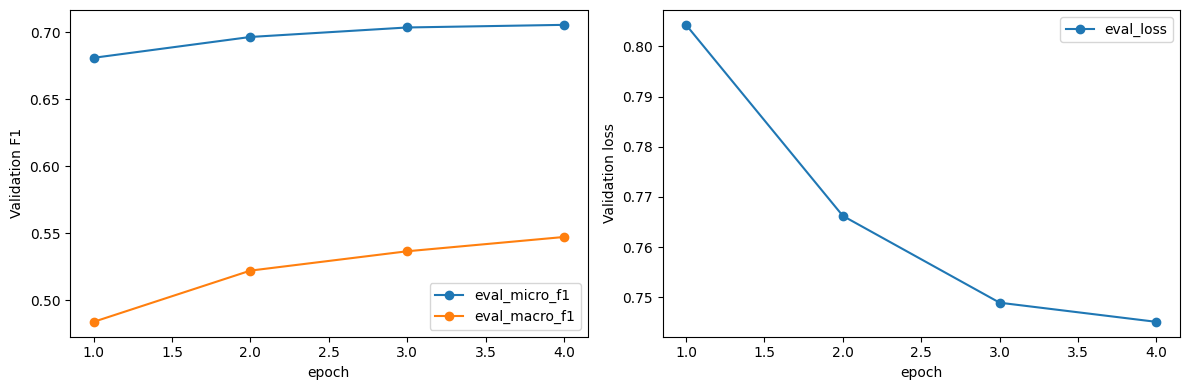

In [10]:
def evaluate_and_save(dataset,frame,prefix):
    output = trainer.predict(dataset,metric_key_prefix=prefix)
    predictions = np.argmax(output.predictions,axis=-1)
    labels = output.label_ids
    assert len(labels)==len(frame), 'Evaluation did not cover all rows.'
    names = [f'{i} star' for i in range(1,6)]
    print(classification_report(labels,predictions,labels=list(range(5)),
                                target_names=names,digits=4,zero_division=0))
    report = classification_report(labels,predictions,labels=list(range(5)),
        target_names=names,output_dict=True,zero_division=0)
    matrix = pd.DataFrame(confusion_matrix(labels,predictions,labels=list(range(5))),
        index=pd.Index(range(1,6),name='Actual'),
        columns=pd.Index(range(1,6),name='Predicted'))
    display(pd.DataFrame([output.metrics]))
    display(matrix)
    (RUN_DIR/f'{prefix}_metrics.json').write_text(json.dumps(output.metrics,indent=2))
    pd.DataFrame(report).T.to_csv(RUN_DIR/f'{prefix}_classification_report.csv')
    matrix.to_csv(RUN_DIR/f'{prefix}_confusion_matrix.csv')
    pd.DataFrame({'source_row_id':frame['source_row_id'].to_numpy(),
                  'actual_rating':labels+1,'predicted_rating':predictions+1
                 }).to_csv(RUN_DIR/f'{prefix}_predictions.csv',index=False)
    return output.metrics

best_validation_metrics = evaluate_and_save(tokenized_datasets['validation'],val_df,'validation')
summary = {
    'run_id':RUN_ID,'model':MODEL_NAME,'split_fingerprint':split_fingerprint,
    'max_length':MAX_LENGTH,'train_batch':TRAIN_BATCH_SIZE,
    'epochs_completed':trainer.state.epoch,
    'best_epoch':float(epoch_results.loc[epoch_results['eval_micro_f1'].idxmax(),'epoch']),
    'training_wall_seconds':elapsed_seconds,'peak_gpu_memory_gb':peak_gpu_memory_gb,
    **best_validation_metrics,
}
pd.DataFrame([summary]).to_csv(RUN_DIR/'comparison_row.csv',index=False)
display(pd.DataFrame([summary]))

import matplotlib.pyplot as plt
fig,axes = plt.subplots(1,2,figsize=(12,4))
epoch_results.plot(x='epoch',y=['eval_micro_f1','eval_macro_f1'],marker='o',ax=axes[0])
epoch_results.plot(x='epoch',y='eval_loss',marker='o',ax=axes[1])
axes[0].set_ylabel('Validation F1'); axes[1].set_ylabel('Validation loss')
fig.tight_layout()
fig.savefig(RUN_DIR/'validation_curves.png',dpi=150)
plt.show()


## 8. Final Test — Optional
Keep this disabled while exploring architectures. Only after finalizing model choices should you set `RUN_TEST` to True and run this cell. Do not use test results to choose the model, batch size, or epoch.


In [11]:
if RUN_TEST:
    test_dataset = Dataset.from_pandas(test_df[['reviewText','labels']],preserve_index=False)
    test_dataset = test_dataset.map(tokenize_batch,batched=True,batch_size=1000,
                                    remove_columns=['reviewText'],desc='Tokenizing final test')
    final_test_metrics = evaluate_and_save(test_dataset,test_df,'test')
else:
    print('Test evaluation is disabled. Use validation during model development.')


Test evaluation is disabled. Use validation during model development.


## 9. Predict a New Review


In [12]:
def predict_rating(text):
    if not isinstance(text,str) or not text.strip():
        raise ValueError('Please provide a non-empty review.')
    inputs = tokenizer(text.strip(),return_tensors='pt',truncation=True,
                       max_length=MAX_LENGTH).to(trainer.model.device)
    trainer.model.eval()
    with torch.inference_mode():
        probabilities = torch.softmax(trainer.model(**inputs).logits,dim=-1)[0].float().cpu().numpy()
    return {'predicted_rating':int(probabilities.argmax())+1,
            'probabilities':{i+1:round(float(p),4) for i,p in enumerate(probabilities)}}

predict_rating('The headphones sound great and the battery lasts all day.')


{'predicted_rating': 5,
 'probabilities': {1: 0.0009, 2: 0.0015, 3: 0.0066, 4: 0.0704, 5: 0.9206}}

## How to Compare Subsequent Experiments

1. Set `REUSE_SPLITS_DIR` to the `splits` directory produced by this run; the dataset fingerprint is also checked.

2. Change one factor at a time and record the seed, splits, selection criterion, and training budget. Changing the training batch size from 32 to 64 is a separate experiment: it changes the number of optimizer steps per epoch. Evaluation batch size only changes how many samples are processed concurrently during evaluation.

3. Compare each run's `comparison_row.csv`: Micro-F1, Macro-F1, MAE, loss, execution time, and memory. Repeat small improvements across multiple seeds; a fixed seed alone does not guarantee completely bitwise-identical runs across GPUs.

4. To compare against older results, rerun the older configuration on the same splits and protocol. Changing both the splits and the number of epochs prevents you from attributing an accuracy increase to just one factor. The previous test set has already been observed; do not use this version's test evaluation for further model tuning.

Core artifacts: `validation_by_epoch.csv`, `validation_metrics.json`, a per-class report and confusion matrix, `comparison_row.csv`, settings and library versions, saved splits, and `best_model`. Drive checkpoints include the best and most recent checkpoints; local Colab files can be lost if the session disconnects. Each notebook execution creates a fresh run; it does not automatically resume from an earlier checkpoint.

References: [Trainer 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer) and [base-model configuration](https://huggingface.co/google/bert_uncased_L-4_H-256_A-4/blob/main/config.json).
